# Baseline do UnimNeuron no Sine_synth

O UnimNeuron-Safe recebe uma observação de cada vez, prevê a classe e só depois atualiza o modelo. A execução de 40 000 observações reproduz a configuração de referência. As duas execuções de 5 000 observações usam o mesmo stream para comparar o efeito do limite de regras.

## Resultados

In [1]:
import json
from pathlib import Path
from IPython.display import Image, Markdown, display

root = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "ENF_UnimNeuron_Safe.py").is_file())
results = root / "results" / "baseline_sine"
summary = json.loads((results / "summary.json").read_text(encoding="utf-8"))

labels = {
    "capped_full": "Limite de 5, baseline completo",
    "capped_quick": "Limite de 5, teste curto",
    "uncapped_quick": "Sem limite, teste curto",
}
lines = [
    "| Configuração | Observações | Accuracy prequential | Regras finais | Tempo |",
    "|---|---:|---:|---:|---:|",
]
for run in summary["runs"]:
    samples = f'{run["samples"]:,}'.replace(",", " ")
    accuracy = f'{run["accuracy"]:.2%}'.replace(".", ",")
    seconds = f'{run["seconds"]:.2f}'.replace(".", ",")
    lines.append(f'| {labels[run["run"]]} | {samples} | {accuracy} | '
                 f'{run["final_rules"]} | {seconds} s |')
display(Markdown("\n".join(lines)))

| Configuração | Observações | Accuracy prequential | Regras finais | Tempo |
|---|---:|---:|---:|---:|
| Limite de 5, baseline completo | 40 000 | 56,72% | 5 | 11,37 s |
| Limite de 5, teste curto | 5 000 | 57,04% | 5 | 1,46 s |
| Sem limite, teste curto | 5 000 | 69,52% | 73 | 12,46 s |

O tempo corresponde à primeira execução de cada configuração. Cada execução foi repetida com a seed 42 e produziu as mesmas previsões e contagens de regras.

## Evolução das regras nos dois testes curtos

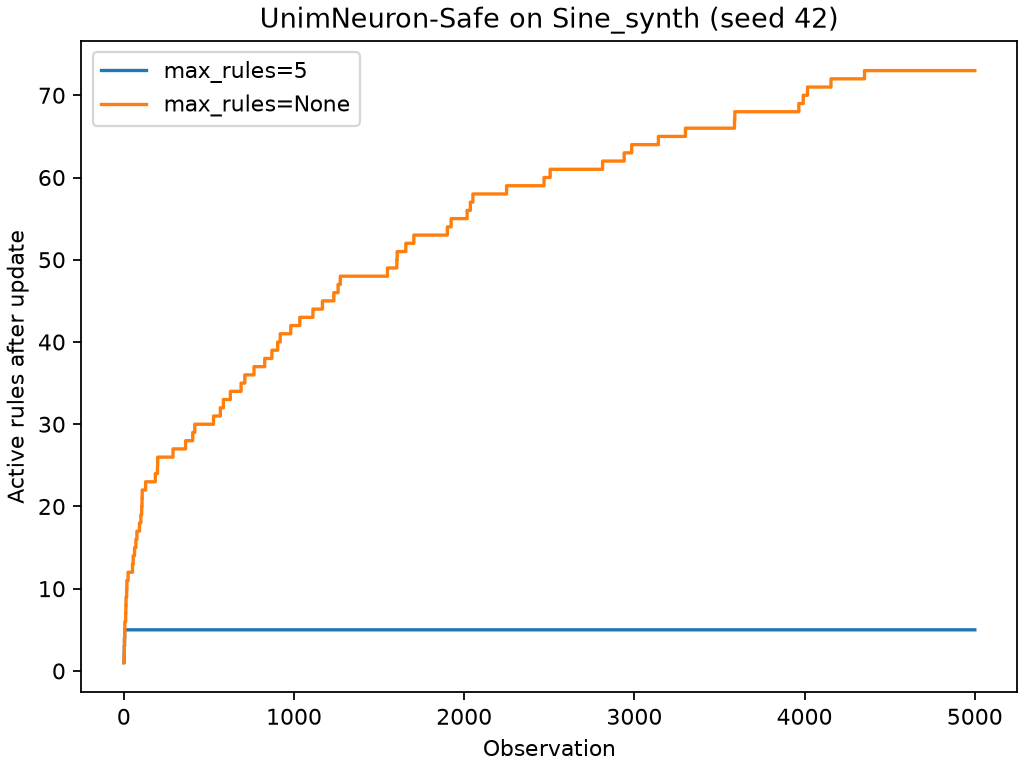

In [2]:
display(Image(filename=str(results / "rule_evolution.png")))

**Interpretação do gráfico acima** Com o limite de cinco regras, o modelo atinge esse valor na quinta observação e mantém a mesma contagem até ao fim. Mesmo com a linha plana, as regras podem ser atualizadas ou substituídas.

Sem limite, o modelo acumula regras mais depressa no início e continua a acrescentá-las a um ritmo mais lento, chegando a 73 ao fim de 5 000 observações. O gráfico mostra quantas regras estão ativas em cada momento. Para avaliar a qualidade das previsões, pode-se consultar  a accuracy prequential na tabela acima.

## Repetir as experiências

Para regenerar os resultados, seleciona o kernel da `.venv` do projeto, muda o valor abaixo para `True` e executa esta célula. A seguir, volta a correr as células da tabela e do gráfico. Os tempos podem variar.

In [3]:
import subprocess
import sys

repeat_experiments = True
if repeat_experiments:
    subprocess.run([sys.executable, str(root / "experiments" / "baseline_sine.py")],
                   cwd=root, check=True)